# Weak Supervision for SMS Spam, Part 1: Labeling Functions

In this notebook I build a training set for an SMS spam filter without hand labeling the training data. Instead I write **labeling functions (LFs)**: small rules that vote `SPAM`, `HAM`, or abstain. Snorkel's `LabelModel` combines those noisy votes into one probabilistic label per message, and then I train a normal classifier on those labels.

The structure follows the Snorkel spam tutorial from the course repo, but the data is the UCI SMS Spam Collection instead of YouTube comments.

Plan:
1. Load the data and check the splits
2. Develop a first LF step by step on the dev set
3. Write the full LF set: keywords, regex, heuristics, ham signals and preprocessor LFs
4. Analyze the LFs
5. Combine the votes with majority vote and with the `LabelModel`
6. Train end models on the weak labels and compare them with two reference points

In [1]:
%matplotlib inline

import os
import random
import warnings

import numpy as np
import pandas as pd

os.environ["PYTHONHASHSEED"] = "0"
random.seed(123)
np.random.seed(123)

warnings.filterwarnings("ignore", category=FutureWarning)
# numpy on macOS prints harmless matmul warnings inside Snorkel's LabelModel
warnings.filterwarnings("ignore", message=".*encountered in matmul")
pd.set_option("display.max_colwidth", 100)

TextBlob, NLTK and spaCy need some data files. This downloads whatever is missing (the spaCy English model and WordNet), so a fresh environment works without extra setup.

In [2]:
from utils import download_nlp_resources

download_nlp_resources()

## 1. Loading the data

`data/sms_spam.csv` has 5,574 messages with a `text` column and a `label` column (0 = ham, 1 = spam). `load_spam_dataset` drops exact duplicate messages, then makes stratified splits with a fixed seed:

- **train**: the big pool I want to label. Its labels are replaced with -1, so I can't peek at them while writing LFs.
- **dev**: 300 labeled messages sampled from train. This is where I read examples and check LF accuracy.
- **valid**: labeled, only used to pick hyperparameters.
- **test**: labeled, only used for the final numbers.

In [3]:
from utils import load_spam_dataset

df_raw = pd.read_csv("data/sms_spam.csv")
df_train, df_dev, df_valid, df_test = load_spam_dataset(split_dev_valid=True)

Y_dev = df_dev.label.values
Y_valid = df_valid.label.values
Y_test = df_test.label.values

splits = {"train": df_train, "dev": df_dev, "valid": df_valid, "test": df_test}
split_table = pd.DataFrame(
    {
        "messages": [len(d) for d in splits.values()],
        "label values": [sorted(d.label.unique().tolist()) for d in splits.values()],
        "spam rate": [round((d.label == 1).mean(), 3) for d in splits.values()],
    },
    index=splits.keys(),
)
print(f"Raw messages: {len(df_raw)}, after dropping duplicates: {len(df_raw.drop_duplicates('text'))}")
split_table

Raw messages: 5574, after dropping duplicates: 5171


,messages,label values,spam rate
train,3619,[-1],0.000
dev,300,"[0, 1]",0.127
valid,517,"[0, 1]",0.126
test,1035,"[0, 1]",0.127


Train only contains -1, as intended. The labeled splits are about 12.6% spam, so the classes are far from balanced (the original YouTube data was close to 50/50). That changes how I read results: a model that always says ham already gets about 87% accuracy, so I report F1 on the spam class next to accuracy.

In [4]:
ABSTAIN = -1
HAM = 0
SPAM = 1

## 2. Writing labeling functions

### Looking at examples

Before writing rules I read a few dev messages from each class.

In [5]:
df_dev[df_dev.label == SPAM].sample(8, random_state=1)[["text"]]

,text
9,"URGENT. Important information for 02 user. Today is your lucky day! 2 find out why , log onto ht..."
219,Call FREEPHONE 0800 542 0578 now!
14,UR GOING 2 BAHAMAS! CallFREEFONE 08081560665 and speak to a live operator to claim either Bahama...
169,"tddnewsletter@emc1.co.uk (More games from TheDailyDraw) Dear Helen, Dozens of Free Games - with ..."
179,Dear Voucher Holder 2 claim your 1st class airport lounge passes when using Your holiday voucher...
200,Free 1st week entry 2 TEXTPOD 4 a chance 2 win 40GB iPod or £250 cash every wk. Txt POD to 84128...
149,Do you want a New Nokia 3510i colour phone DeliveredTomorrow? With 300 free minutes to any mobil...
240,SMS AUCTION - A BRAND NEW Nokia 7250 is up 4 auction today! Auction is FREE 2 join & take part! ...


In [6]:
df_dev[df_dev.label == HAM].sample(8, random_state=1)[["text"]]

,text
296,I'm stuck in da middle of da row on da right hand side of da lt...
17,"Sez, hows u & de arab boy? Hope u r all good give my love 2 evry1 love ya eshxxxxxxxxxxx"
139,Hey you told your name to gautham ah?
81,Is ur changes 2 da report big? Cos i've already made changes 2 da previous report.
272,Yes. Nigh you cant aha.
108,Goin to workout lor... Muz lose e fats...
268,I'm awake oh. What's up.
292,Send to someone else :-)


Spam wants you to *do* something: call a number, text a short code, claim a prize. It tends to be long, full of digits, and uses words like FREE and WIN. Ham is casual: short replies, slang like "lor" and "ok", and lots of "I" and "me".

### A first LF: the word "call"

Lots of spam says "call 0906...", so a natural first rule is: if the message contains the word *call*, vote spam. Below is that version and a stricter one that needs a long number after the word.

In [7]:
import re

from snorkel.labeling import labeling_function


@labeling_function()
def call(x):
    return SPAM if re.search(r"\bcall\b", x.text, flags=re.I) else ABSTAIN


@labeling_function()
def regex_call_number(x):
    return SPAM if re.search(r"\bcall\D{0,20}\d{5,}", x.text, flags=re.I) else ABSTAIN

`PandasLFApplier` runs a list of LFs over a DataFrame and returns the **label matrix** `L`: one row per message, one column per LF, and each cell holds that LF's vote (or -1).

In [8]:
from snorkel.labeling import LFAnalysis, PandasLFApplier

lfs = [call, regex_call_number]

applier = PandasLFApplier(lfs=lfs)
L_train = applier.apply(df=df_train, progress_bar=False)
L_dev = applier.apply(df=df_dev, progress_bar=False)
L_train[:5]

array([[-1, -1],
       [-1, -1],
       [-1, -1],
       [-1, -1],
       [-1, -1]])

On train I can only measure coverage, overlaps and conflicts, because there are no labels.

In [9]:
LFAnalysis(L=L_train, lfs=lfs).lf_summary()

,j,Polarity,Coverage,Overlaps,Conflicts
call,0,[1],0.088975,0.043935,0.0
regex_call_number,1,[1],0.044487,0.043935,0.0


This is what the dev set is for. With gold labels, `lf_summary` also reports how often each LF is right when it votes.

In [10]:
LFAnalysis(L=L_dev, lfs=lfs).lf_summary(Y=Y_dev)

,j,Polarity,Coverage,Overlaps,Conflicts,Correct,Incorrect,Emp. Acc.
call,0,[1],0.073333,0.046667,0.0,16,6,0.727273
regex_call_number,1,[1],0.050000,0.046667,0.0,15,0,1.000000


The plain `call` rule covers more messages but gets a fair share of them wrong. `get_label_buckets` groups messages by (gold label, LF vote), so I can pull out the ham messages that `call` voted spam on.

In [11]:
from snorkel.analysis import get_label_buckets

buckets = get_label_buckets(Y_dev, L_dev[:, 0])
df_dev.iloc[buckets[(HAM, SPAM)]][["text"]]

,text
145,HI DARLIN HOW WAS WORK DID U GET INTO TROUBLE? IJUST TALKED TO YOUR MUM ALL MORNING! I HAD A REA...
159,"Call me. I m unable to cal. Lets meet bhaskar, and deep"
238,So now my dad is gonna call after he gets out of work and ask all these crazy questions.
259,Sorry i missed your call. Can you please call back.
287,You call him now ok i said call him
294,You call him and tell now infront of them. Call him now.


These are people saying things like "sorry I missed your call" or "you call him now". Requiring a number right after *call* removes them, and on dev the regex version never votes spam on a ham message. I keep `regex_call_number` and drop the plain keyword. It's the same coverage vs precision trade-off the original lab showed with "check" and "check out".

### LFs that use a preprocessor

A Snorkel `Preprocessor` adds new fields to a data point before the LF sees it. Here TextBlob adds a polarity score (-1 to 1) and a subjectivity score (0 to 1). `memoize=True` caches the result, so TextBlob runs once per message even though two LFs use it.

My guess for polarity: spam is relentlessly upbeat ("Congratulations!"), so a clearly negative message is probably from a real person. For subjectivity I reuse the original lab's rule that opinionated text leans ham.

In [12]:
from snorkel.preprocess import preprocessor
from textblob import TextBlob


@preprocessor(memoize=True)
def textblob_sentiment(x):
    scores = TextBlob(x.text)
    x.polarity = scores.sentiment.polarity
    x.subjectivity = scores.sentiment.subjectivity
    return x


@labeling_function(pre=[textblob_sentiment])
def textblob_polarity(x):
    return HAM if x.polarity < -0.1 else ABSTAIN


@labeling_function(pre=[textblob_sentiment])
def textblob_subjectivity(x):
    return HAM if x.subjectivity >= 0.5 else ABSTAIN

In [13]:
lfs = [textblob_polarity, textblob_subjectivity]

applier = PandasLFApplier(lfs)
L_dev = applier.apply(df_dev, progress_bar=False)
LFAnalysis(L_dev, lfs).lf_summary(Y=Y_dev)

,j,Polarity,Coverage,Overlaps,Conflicts,Correct,Incorrect,Emp. Acc.
textblob_polarity,0,[0],0.126667,0.086667,0.0,33,5,0.868421
textblob_subjectivity,1,[0],0.440000,0.086667,0.0,108,24,0.818182


Both are weak. Since about 87% of dev is ham, a ham LF has to beat 0.87 accuracy to tell me anything new. Polarity sits right around that line and subjectivity is below it. I keep both anyway, to see whether the `LabelModel` learns to trust them less.

## 3. The full set of labeling functions

### a) Keyword LFs

All keyword LFs share the same logic, so like the original I write one lookup function and build each LF with `LabelingFunction` and its `resources` argument. One change: I match whole words instead of substrings, otherwise *win* would also fire on *window* and *wine*.

*attempt* is in the urgent list because a lot of prize spam says "2nd attempt to contact u".

In [14]:
from snorkel.labeling import LabelingFunction


def keyword_lookup(x, keywords, label):
    words = set(re.findall(r"[a-z0-9']+", x.text.lower()))
    return label if words & set(keywords) else ABSTAIN


def make_keyword_lf(keywords, label=SPAM, name=None):
    return LabelingFunction(
        name=name or f"keyword_{keywords[0]}",
        f=keyword_lookup,
        resources=dict(keywords=keywords, label=label),
    )


keyword_free = make_keyword_lf(["free", "freemsg", "freephone"])
keyword_win = make_keyword_lf(["win", "winner", "won", "wins", "winning"])
keyword_prize = make_keyword_lf(["prize", "prizes", "award", "awarded", "guaranteed", "bonus"])
keyword_claim = make_keyword_lf(["claim", "claims", "redeem"])
keyword_urgent = make_keyword_lf(["urgent", "attempt", "expires", "immediately"])
keyword_txt = make_keyword_lf(["txt", "sms"])
keyword_reply = make_keyword_lf(["reply", "rply"])
keyword_cash = make_keyword_lf(["cash", "pounds", "gbp"])
keyword_offer = make_keyword_lf(["offer", "discount", "voucher", "vouchers", "deal"])
keyword_mobile = make_keyword_lf(["mobile", "ringtone", "tones", "nokia", "camcorder"])

The same template works for ham. Texting slang and first person pronouns are things friends write and marketing messages mostly don't.

In [15]:
texting_slang = make_keyword_lf(
    ["lol", "ok", "okay", "k", "haha", "hahaha", "lor", "lar", "i'll", "gonna", "wat", "hmm", "da", "dun"],
    label=HAM,
    name="texting_slang",
)
first_person = make_keyword_lf(
    ["i", "me", "my", "i'm", "im", "i've", "myself"],
    label=HAM,
    name="first_person",
)

### b) Regex LFs

SMS spam almost always tells you how to respond, so a lot of its structure is in numbers and links: UK premium numbers like 09061701461, five digit short codes ("text WIN to 80086"), prices like £1.50, and web addresses.

In [16]:
def regex_lookup(x, pattern):
    return SPAM if re.search(pattern, x.text, flags=re.I) else ABSTAIN


def make_regex_lf(name, pattern):
    return LabelingFunction(name=name, f=regex_lookup, resources=dict(pattern=pattern))


regex_phone_number = make_regex_lf("regex_phone_number", r"(?<!\d)(?:0|\+44)\d{3,4}\s?\d{3}\s?\d{3,4}(?!\d)")
regex_short_code = make_regex_lf("regex_short_code", r"(?<!\d)\d{5}(?!\d)")
regex_currency = make_regex_lf("regex_currency", r"[£$€]\s?\d")
regex_url = make_regex_lf("regex_url", r"https?://|www\.|\b\w+\.(?:com|net|org|co\.uk|biz|info)\b")

### c) Heuristic LFs

These look at the shape of a message instead of its words: length, share of uppercase letters, and share of digits.

The uppercase rule took a detour. My first version was "more than half the letters are uppercase means spam", but on dev those messages were mostly ham, people texting in all caps. The table below shows the spam rate on dev by uppercase share.

In [17]:
def uppercase_share(text):
    letters = [c for c in text if c.isalpha()]
    if not letters:
        return 0.0, 0
    return sum(c.isupper() for c in letters) / len(letters), len(letters)


share = df_dev.text.map(lambda t: uppercase_share(t)[0])
bands = pd.cut(share, [0, 0.1, 0.2, 0.5, 1.0], include_lowest=True)
df_dev.groupby(bands, observed=True).label.agg(messages="size", spam_rate="mean").round(2)

,messages,spam_rate
text,,
"(-0.001, 0.1]",239,0.04
"(0.1, 0.2]",33,0.45
"(0.2, 0.5]",16,0.69
"(0.5, 1.0]",12,0.17


Spam mixes normal text with a few shouted words (FREE, WIN, URGENT), so the spam rate peaks in the middle band and falls again for mostly uppercase text. The final rule fires on a 20% to 50% uppercase share.

`long_message` is noisy on its own, since plenty of friends write long texts. But only about 13% of messages are spam, so if around half of the long ones are spam that is still a big jump over the base rate. A weak but informative LF like this is exactly what the `LabelModel` is meant to weigh.

In [18]:
@labeling_function()
def long_message(x):
    return SPAM if len(x.text) > 130 else ABSTAIN


@labeling_function()
def uppercase_ratio(x):
    share, n_letters = uppercase_share(x.text)
    return SPAM if n_letters >= 15 and 0.2 <= share <= 0.5 else ABSTAIN


@labeling_function()
def digit_ratio(x):
    digits = sum(c.isdigit() for c in x.text)
    return SPAM if digits / max(len(x.text), 1) > 0.08 else ABSTAIN


@labeling_function()
def short_message(x):
    return HAM if len(x.text.split()) < 5 else ABSTAIN

### d) An LF with a spaCy preprocessor

Like the original, I also use spaCy through Snorkel's `nlp_labeling_function`, which parses each message once and hands the LF a spaCy `Doc` in `x.doc`. A short message that mentions someone by name ("Tell Anna I'm late") is usually from a friend.

In [19]:
from snorkel.labeling.lf.nlp import nlp_labeling_function


@nlp_labeling_function()
def has_person_nlp(x):
    if len(x.doc) < 20 and any(ent.label_ == "PERSON" for ent in x.doc.ents):
        return HAM
    return ABSTAIN

### Putting them together

24 LFs in total: 15 that vote spam (keywords and regex), 3 spam heuristics, and 6 that vote ham.

In [20]:
lfs = [
    keyword_free,
    keyword_win,
    keyword_prize,
    keyword_claim,
    keyword_urgent,
    keyword_txt,
    keyword_reply,
    keyword_cash,
    keyword_offer,
    keyword_mobile,
    regex_call_number,
    regex_phone_number,
    regex_short_code,
    regex_currency,
    regex_url,
    long_message,
    uppercase_ratio,
    digit_ratio,
    short_message,
    texting_slang,
    first_person,
    textblob_polarity,
    textblob_subjectivity,
    has_person_nlp,
]

applier = PandasLFApplier(lfs=lfs)
L_train = applier.apply(df=df_train, progress_bar=False)
L_dev = applier.apply(df=df_dev, progress_bar=False)
L_test = applier.apply(df=df_test, progress_bar=False)
L_train.shape

(3619, 24)

## 4. Analyzing the LFs

Coverage, overlaps and conflicts come from train (no labels needed). Correct, incorrect and empirical accuracy come from dev.

In [21]:
train_summary = LFAnalysis(L=L_train, lfs=lfs).lf_summary()
dev_summary = LFAnalysis(L=L_dev, lfs=lfs).lf_summary(Y=Y_dev)

lf_table = pd.DataFrame(
    {
        "polarity": train_summary["Polarity"],
        "coverage": train_summary["Coverage"],
        "overlaps": train_summary["Overlaps"],
        "conflicts": train_summary["Conflicts"],
        "dev_correct": dev_summary["Correct"],
        "dev_incorrect": dev_summary["Incorrect"],
        "dev_accuracy": dev_summary["Emp. Acc."],
    }
)
lf_table.round(3)

,polarity,coverage,overlaps,conflicts,dev_correct,dev_incorrect,dev_accuracy
keyword_free,[1],0.044,0.044,0.041,11,2,0.846
keyword_win,[1],0.026,0.025,0.014,5,0,1.000
keyword_prize,[1],0.024,0.024,0.014,5,0,1.000
keyword_claim,[1],0.019,0.019,0.011,6,0,1.000
keyword_urgent,[1],0.017,0.017,0.010,9,1,0.900
keyword_txt,[1],0.035,0.035,0.022,9,1,0.900
keyword_reply,[1],0.025,0.025,0.018,6,0,1.000
keyword_cash,[1],0.016,0.015,0.011,7,1,0.875
keyword_offer,[1],0.012,0.012,0.007,3,1,0.750
keyword_mobile,[1],0.037,0.037,0.026,11,1,0.917


In [22]:
total_coverage = LFAnalysis(L=L_train, lfs=lfs).label_coverage()
print(f"Train messages with at least one LF vote: {total_coverage:.1%}")

Train messages with at least one LF vote: 85.4%


The same numbers as a chart, saved to `results/lf_analysis.png`. The dashed lines are the base rates on dev: a spam LF has to land to the right of the orange line and a ham LF to the right of the blue line to add information.

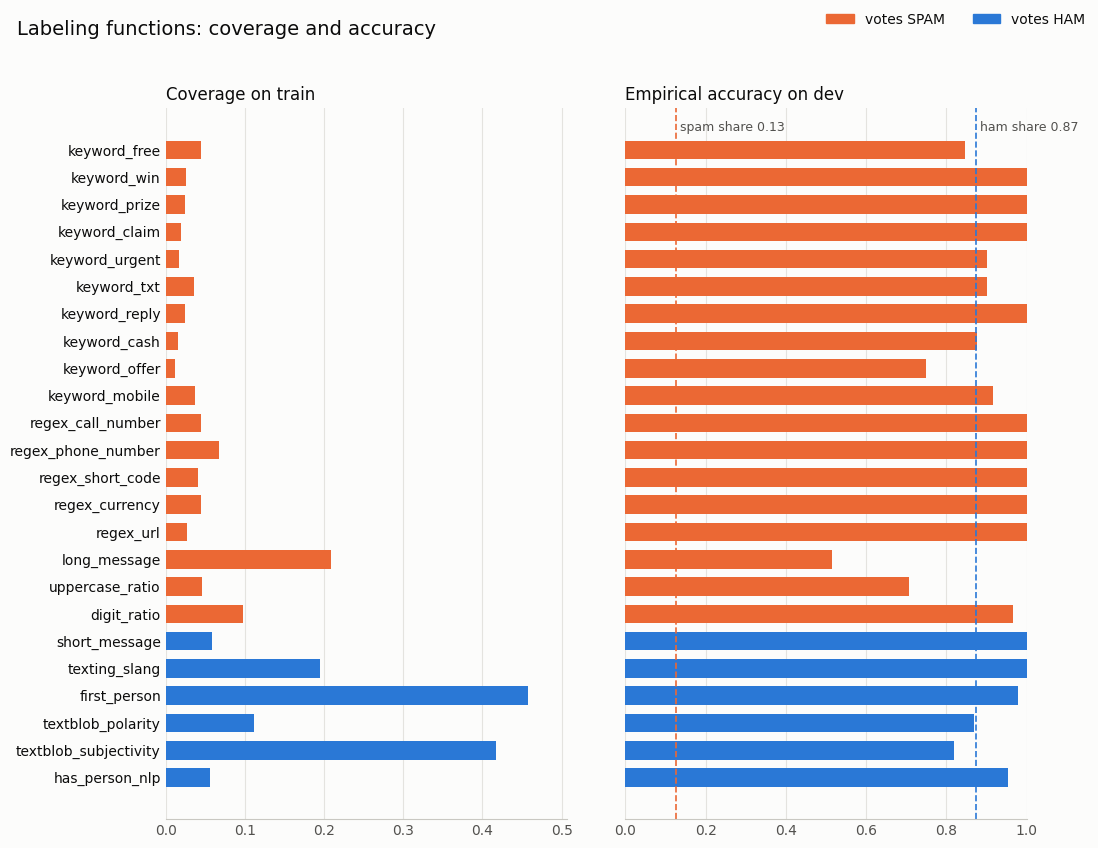

In [23]:
import matplotlib.pyplot as plt

os.makedirs("results", exist_ok=True)

SPAM_COLOR = "#eb6834"
HAM_COLOR = "#2a78d6"
INK = "#0b0b0b"
MUTED = "#52514e"
SURFACE = "#fcfcfb"

names = lf_table.index[::-1]
colors = [SPAM_COLOR if lf_table.loc[n, "polarity"] == [SPAM] else HAM_COLOR for n in names]
spam_rate_dev = Y_dev.mean()

fig, axes = plt.subplots(1, 2, figsize=(11, 8.5), sharey=True, facecolor=SURFACE)
panels = [
    ("coverage", "Coverage on train"),
    ("dev_accuracy", "Empirical accuracy on dev"),
]
for ax, (col, title) in zip(axes, panels):
    ax.set_facecolor(SURFACE)
    ax.barh(names, lf_table.loc[names, col], color=colors, height=0.68)
    ax.set_title(title, loc="left", color=INK, fontsize=12)
    ax.set_xlim(0, 1 if col == "dev_accuracy" else max(0.5, lf_table[col].max() + 0.05))
    ax.grid(axis="x", color="#e4e3df", linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ["top", "right", "left"]:
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color("#c9c8c2")
    ax.tick_params(colors=MUTED, length=0)
    ax.tick_params(axis="y", labelcolor=INK)

acc_ax = axes[1]
for rate, color, label in [(spam_rate_dev, SPAM_COLOR, "spam share"), (1 - spam_rate_dev, HAM_COLOR, "ham share")]:
    acc_ax.axvline(rate, color=color, linestyle="--", linewidth=1.2)
    acc_ax.text(rate + 0.01, len(names) - 0.4, f"{label} {rate:.2f}", color=MUTED, fontsize=9, va="bottom")

handles = [plt.Rectangle((0, 0), 1, 1, color=SPAM_COLOR), plt.Rectangle((0, 0), 1, 1, color=HAM_COLOR)]
fig.legend(handles, ["votes SPAM", "votes HAM"], loc="upper right", frameon=False, ncol=2, labelcolor=INK)
fig.suptitle("Labeling functions: coverage and accuracy", x=0.02, ha="left", color=INK, fontsize=14)
fig.tight_layout(rect=(0, 0, 1, 0.96), w_pad=3)
fig.savefig("results/lf_analysis.png", dpi=150, facecolor=SURFACE)
plt.show()

What stands out:
- The regex LFs (call numbers, phone numbers, short codes, prices, links) are right every time they fire on dev, but each one covers only a few percent of train.
- `long_message` is the noisiest LF at about 0.52 accuracy and has the most conflicts, yet it is still far to the right of the 0.13 spam line.
- `first_person` and `texting_slang` carry most of the ham labeling, with big coverage and high accuracy.
- `textblob_subjectivity` covers 42% of train but lands left of the ham line, so it is mostly noise.

The histogram below counts how many LFs voted on each train message. Messages with zero votes carry no signal and get dropped before training the end model.

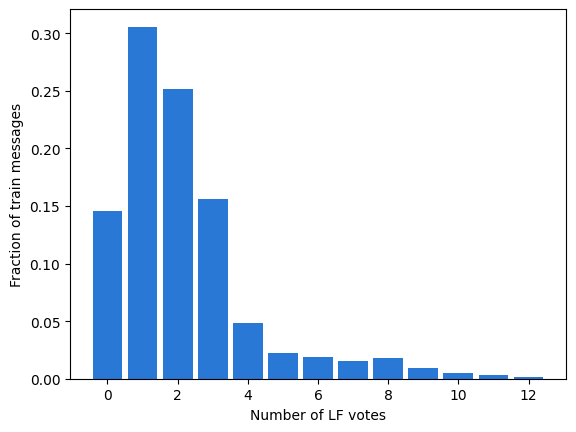

In [24]:
def plot_label_frequency(L):
    counts = (L != ABSTAIN).sum(axis=1)
    plt.hist(counts, bins=np.arange(counts.max() + 2) - 0.5, density=True, color=HAM_COLOR, rwidth=0.85)
    plt.xlabel("Number of LF votes")
    plt.ylabel("Fraction of train messages")
    plt.show()


plot_label_frequency(L_train)

## 5. Combining the LF votes

The simplest way to combine votes is a majority vote per message. `MajorityLabelVoter` does that, but it treats every LF as equally good.

The `LabelModel` instead estimates how accurate each LF is from the pattern of agreements and disagreements on train, without seeing any gold labels, and weights the votes accordingly.

In [25]:
from snorkel.labeling.model import LabelModel, MajorityLabelVoter

majority_model = MajorityLabelVoter()

label_model = LabelModel(cardinality=2, verbose=False)
label_model.fit(L_train=L_train, n_epochs=500, log_freq=100, seed=123, progress_bar=False)

The original lab fits the `LabelModel` with the default class prior, which assumes both classes are equally common. That was reasonable for YouTube comments, but SMS is only about 13% spam. `fit` can take the dev labels through `Y_dev` and estimate the class balance from them, so I also fit a second model that way.

In [26]:
label_model_dev = LabelModel(cardinality=2, verbose=False)
label_model_dev.fit(L_train=L_train, Y_dev=Y_dev, n_epochs=500, log_freq=100, seed=123, progress_bar=False)
print("Class balance estimated from dev:", np.round(label_model_dev.p, 3))

Class balance estimated from dev: [0.873 0.127]


Now all three on the test set. Like the original, ties (including messages where every LF abstains) are broken at random.

In [27]:
combiners = {
    "Majority vote": majority_model,
    "LabelModel (default prior)": label_model,
    "LabelModel (class balance from dev)": label_model_dev,
}
label_scores = pd.DataFrame(
    {
        name: model.score(L=L_test, Y=Y_test, tie_break_policy="random", metrics=["accuracy", "f1"])
        for name, model in combiners.items()
    }
).T
label_scores.round(3)

,accuracy,f1
Majority vote,0.864,0.638
LabelModel (default prior),0.685,0.440
LabelModel (class balance from dev),0.964,0.871


This is the biggest difference from the original lab. With the default prior, the `LabelModel` is worse than a plain majority vote (accuracy 0.685 vs 0.864). Assuming half the messages are spam pushes too many borderline messages over the line. Once it knows spam is only about 13% of messages, it beats majority vote by a wide margin (F1 0.871 vs 0.638). Majority vote's accuracy is actually below the 0.873 you get by always answering ham, another reason to watch F1 here.

From here on I use the model fit with the dev class balance.

The `LabelModel` outputs probabilities, not hard labels. The histogram shows how sure it is that each train message is spam.

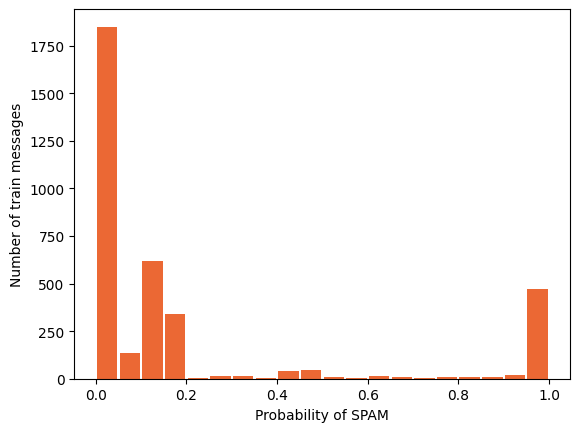

In [28]:
probs_train = label_model_dev.predict_proba(L=L_train)

plt.hist(probs_train[:, SPAM], bins=20, color=SPAM_COLOR, rwidth=0.9)
plt.xlabel("Probability of SPAM")
plt.ylabel("Number of train messages")
plt.show()

### Filtering out unlabeled messages

Messages that no LF voted on just get the class prior back from the `LabelModel`, which is no real signal. Snorkel's `filter_unlabeled_dataframe` drops them.

In [29]:
from snorkel.labeling import filter_unlabeled_dataframe

df_train_filtered, probs_train_filtered = filter_unlabeled_dataframe(
    X=df_train, y=probs_train, L=L_train
)
print(f"Kept {len(df_train_filtered)} of {len(df_train)} train messages")

Kept 3092 of 3619 train messages


## 6. Training end models

The label model can only label messages that some LF votes on, and it needs every LF at prediction time. An end model trained on its labels only needs the raw text, so it can generalize past the rules.

I compare two end models:
- **Bag of n-grams + LogisticRegression**: the original lab's model (`CountVectorizer` with 1 to 5 word n-grams, `C=1000`).
- **TF-IDF + LogisticRegression**: my version, combining word 1-2 grams with character 2-5 grams. Character n-grams should cope better with SMS spelling (txt, 2nite, 150p/msg). `C` is picked on the valid set.

Like the original, I turn the probabilities into hard labels with `probs_to_preds`, because scikit-learn wants class labels.

In [30]:
from snorkel.utils import probs_to_preds

preds_train_filtered = probs_to_preds(probs=probs_train_filtered)
print(f"Weak labels: {preds_train_filtered.mean():.1%} spam")

Weak labels: 18.0% spam


In [31]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.linear_model import LogisticRegression

from utils import binary_scores, make_tfidf


def train_bow(texts, labels):
    vectorizer = CountVectorizer(ngram_range=(1, 5))
    model = LogisticRegression(C=1e3, solver="liblinear")
    model.fit(vectorizer.fit_transform(texts), labels)
    return vectorizer, model


def train_tfidf(texts, labels, c_grid=(0.1, 1, 10, 100)):
    vectorizer = make_tfidf()
    X = vectorizer.fit_transform(texts)
    X_valid = vectorizer.transform(df_valid.text)
    best_f1, best_c, best_model = -1, None, None
    for c in c_grid:
        model = LogisticRegression(C=c, solver="liblinear").fit(X, labels)
        f1 = binary_scores(Y_valid, model.predict(X_valid))["f1"]
        if f1 > best_f1:
            best_f1, best_c, best_model = f1, c, model
    return vectorizer, best_model, best_c


def test_scores(vectorizer, model):
    return binary_scores(Y_test, model.predict(vectorizer.transform(df_test.text)))

In [32]:
results = {}
chosen_c = {}

vec, model = train_bow(df_train_filtered.text, preds_train_filtered)
results[("weak labels", "BoW + LR (original)")] = test_scores(vec, model)

vec, model, chosen_c["weak labels"] = train_tfidf(df_train_filtered.text, preds_train_filtered)
results[("weak labels", "TF-IDF + LR")] = test_scores(vec, model)

print("C picked on valid:", chosen_c["weak labels"])
pd.DataFrame(results).T

C picked on valid: 10


accuracy  precision  recall      f1
weak labels BoW + LR (original)    0.9710     0.9903  0.7786  0.8718
            TF-IDF + LR            0.9874     0.9836  0.9160  0.9486

### Two reference points

To judge the weak labels I need something to compare them with:
- **Dev only**: train on just the 300 hand labeled dev messages. This is what I could do without Snorkel, with only the labels I already have.
- **Fully supervised**: train on the real labels of the whole train split. This is the upper bound, what I'd get by paying someone to label all 3,619 messages. I load these labels only here, after all the LF work is done.

In [33]:
df_train_gold, _ = load_spam_dataset(load_train_labels=True)

for source, df in [("dev only", df_dev), ("fully supervised", df_train_gold)]:
    vec, model = train_bow(df.text, df.label)
    results[(source, "BoW + LR (original)")] = test_scores(vec, model)
    vec, model, chosen_c[source] = train_tfidf(df.text, df.label)
    results[(source, "TF-IDF + LR")] = test_scores(vec, model)

end_models = pd.DataFrame(results).T.loc[["dev only", "weak labels", "fully supervised"]]
print("C picked on valid:", chosen_c)
end_models

C picked on valid: {'weak labels': 10, 'dev only': 100, 'fully supervised': 10}


accuracy  precision  recall      f1
dev only         BoW + LR (original)    0.8870     1.0000  0.1069  0.1931
                 TF-IDF + LR            0.9594     1.0000  0.6794  0.8091
weak labels      BoW + LR (original)    0.9710     0.9903  0.7786  0.8718
                 TF-IDF + LR            0.9874     0.9836  0.9160  0.9486
fully supervised BoW + LR (original)    0.9700     1.0000  0.7634  0.8658
                 TF-IDF + LR            0.9836     0.9914  0.8779  0.9312

Reading the table:
- **Weak labels vs dev only.** With just the 300 dev labels, the original bag-of-n-grams model finds only about 11% of the spam (recall 0.107). The same model trained on Snorkel's labels reaches F1 0.872. Writing 24 LFs bought far more than hand labeling 300 messages.
- **Weak labels vs fully supervised.** The weak-label models match the fully supervised ones, and the TF-IDF model is even a bit better on test (F1 0.949 vs 0.931), mostly through higher recall. The weak labels are 18% spam, more than the real 12.6%, so a model trained on them leans toward calling things spam. With only 131 spam messages in test I read this as a tie, not a win.
- **TF-IDF vs the original model.** TF-IDF with character n-grams is better in every row, and the gap is largest when labels are scarce (dev only: F1 0.809 vs 0.193).

## Saving the numbers

Everything important goes into `results/metrics.json`, which the README tables are built from.

In [34]:
from utils import save_metrics


def clean(value):
    return None if pd.isna(value) else round(float(value), 4)


save_metrics(
    "dataset",
    {
        "raw_messages": len(df_raw),
        "raw_spam": int(df_raw.label.sum()),
        "after_dedup": int(len(df_raw.drop_duplicates("text"))),
        "splits": {
            name: {
                "messages": len(d),
                "spam": None if name == "train" else int(d.label.sum()),
                "spam_rate": None if name == "train" else clean(d.label.mean()),
            }
            for name, d in splits.items()
        },
        "train_spam_rate_hidden": clean(df_train_gold.label.mean()),
    },
)

metrics = save_metrics(
    "labeling",
    {
        "n_lfs": len(lfs),
        "train_coverage": clean(total_coverage),
        "train_kept_after_filter": len(df_train_filtered),
        "weak_label_spam_rate": clean(preds_train_filtered.mean()),
        "lf_summary": {
            name: {
                "polarity": "SPAM" if row["polarity"] == [SPAM] else "HAM",
                "coverage": clean(row["coverage"]),
                "overlaps": clean(row["overlaps"]),
                "conflicts": clean(row["conflicts"]),
                "dev_correct": int(row["dev_correct"]),
                "dev_incorrect": int(row["dev_incorrect"]),
                "dev_accuracy": clean(row["dev_accuracy"]),
            }
            for name, row in lf_table.iterrows()
        },
        "label_model_test": {
            name: {k: clean(v) for k, v in row.items()} for name, row in label_scores.iterrows()
        },
        "class_balance_from_dev": [clean(p) for p in label_model_dev.p],
        "end_models_test": {
            source: {name: end_models.loc[(source, name)].to_dict() for name in end_models.loc[source].index}
            for source in ["dev only", "weak labels", "fully supervised"]
        },
        "tfidf_c_picked_on_valid": chosen_c,
    },
)
print(list(metrics))

['dataset', 'labeling', 'augmentation', 'slicing']


## Summary

- 24 LFs give at least one vote to 85% of the unlabeled train set, with no hand labeling of train.
- On SMS the `LabelModel` only pays off once it knows the class balance. With the default prior it loses to majority vote.
- End models trained on the weak labels reach the level of models trained on the real train labels, and are far ahead of what 300 hand labels give.
- TF-IDF with word and character n-grams beats the original bag-of-n-grams model in every setting.

Part 2 looks at making the training set bigger with data augmentation.